In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd .read_csv('creditcard.csv')

In [7]:
print(df.shape)

(284807, 31)


In [8]:
print(df.head())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [9]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [11]:
print(df['Class'].value_counts())
print(f"\nFraud percentage: {df['Class'].mean() * 100:.4f}%")

Class
0    284315
1       492
Name: count, dtype: int64

Fraud percentage: 0.1727%


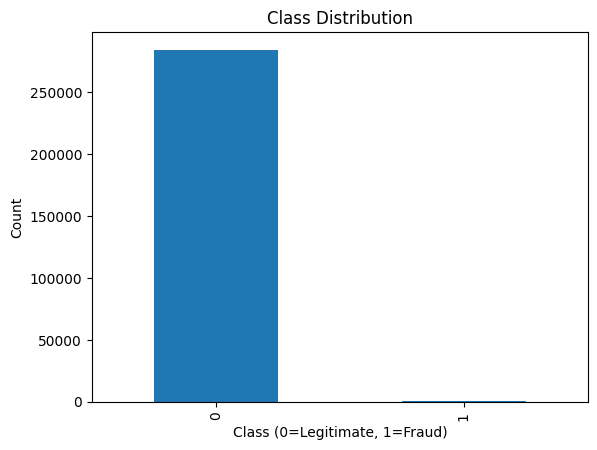

In [12]:
df['Class'].value_counts().plot(kind='bar')
plt.title("Class Distribution")
plt.xlabel("Class (0=Legitimate, 1=Fraud)")
plt.ylabel("Count")
plt.show()

Exactly — 0.17% fraud. That means out of every 10,000 transactions, only 17 are fraudulent.

This is called class imbalance — and it's the central challenge of fraud detection.

Here's why it's a problem:

If your model just predicts "legitimate" for every single transaction — never predicts fraud at all — it would be 99.83% accurate. Sounds great, but it's completely useless. It would miss every single fraud case.

This is why accuracy is a misleading metric for imbalanced datasets. You need better metrics.

The metrics that actually matter for fraud detection:

Precision — of all transactions I flagged as fraud, how many were actually fraud? (avoiding false alarms)

Recall — of all actual frauds, how many did I catch? (catching real fraud)

F1 Score — balance between precision and recall

ROC-AUC — overall model discrimination ability

In fraud detection, recall is usually more important — missing a real fraud (false negative) is worse than a false alarm (false positive).

In [13]:
from sklearn.model_selection import train_test_split

X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set: {X_train.shape}")
print(f"Test set: {X_test.shape}")
print(f"Training fraud cases: {y_train.sum()}")
print(f"Test fraud cases: {y_test.sum()}")

Training set: (227845, 30)
Test set: (56962, 30)
Training fraud cases: 394
Test fraud cases: 98


Here, axis = 1 implies - drop a column and if axis = 0 drop the row 

test_size = 0.2 means to split data into 80% training, 20% testing.

Training set — model learns from this

Test set — model never sees this during training, used only to evaluate real-world performance

random_state=42

The split is random — but random_state fixes that randomness so you get the same split every time you run the code.

Without it: every run gives a different split, results change, hard to reproduce.
With it: same split every time, results are reproducible.

42 is just a convention — any number works.


stratify=y

This is critical for imbalanced datasets.

Without stratify: random split might put most fraud cases in training and very few in test — or vice versa. Test set wouldn't represent real distribution.

With stratify=y: ensures both training and test sets maintain the same fraud ratio (0.17%) as the original dataset. Both sets are representative.

For imbalanced data like fraud detection — always use stratify.

Perfect split — 80/20, and fraud cases are proportionally distributed (394 train, 98 test).

Now let's handle the class imbalance. We'll use a technique called SMOTE — Synthetic Minority Oversampling Technique.

What SMOTE does:

Instead of just duplicating fraud cases (which doesn't add new information), SMOTE creates synthetic fraud cases by interpolating between existing fraud cases. It looks at real fraud transactions, finds similar ones, and generates new ones in between.

Result: balanced dataset where model sees enough fraud examples to learn the pattern.

SMOTE will create synthetic fraud cases to balance the dataset.

from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

print(f"Before SMOTE - Fraud: {y_train.sum()}, Legitimate: {(y_train==0).sum()}")
print(f"After SMOTE - Fraud: {y_train_balanced.sum()}, Legitimate: {(y_train_balanced==0).sum()}")

SMOTE created 227,057 synthetic fraud transactions (227,451 - 394) by interpolating between the 394 real fraud cases. Model now has equal exposure to both classes during training.

Now let's scale the features — remember standardization from week 1? Amount and Time have very different scales than V1-V28, which are already PCA transformed. We need everything on the same scale:

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_balanced)
X_test_scaled = scaler.transform(X_test)

Notice two different calls:

fit_transform on training data — learns mean/std from training, then scales

transform only on test data — uses the same mean/std learned from training

Why do we use fit_transform on training data but only transform on test data?


**The rule: test data must be treated as if it's unseen future data.**

In real world: your model is trained today, deployed tomorrow. Tomorrow's transactions are new — you don't know their mean or std in advance.

So when scaling:

**Training data — `fit_transform`:**
- `fit` — learns mean and std from training data
- `transform` — scales training data using those values

**Test data — `transform` only:**
- Uses the SAME mean and std learned from training
- Does NOT learn new mean/std from test data

**Why not fit on test data too?**

If you fit on test data, you're letting future information leak into your model evaluation. The test set would be scaled differently than real future data would be. Your evaluation becomes unreliable — model looks better than it actually is in production.

This is called **data leakage** — one of the most common and costly mistakes in ML. Models that look great in testing but fail in production often have data leakage.

**Simple analogy:**

You're a teacher standardizing exam scores. You calculate the class average from students who already took the exam (training). When next year's students take the exam, you use last year's average to standardize their scores — not recalculate a new average from them.

Always fit on training, transform on test. Never the other way around.
